In [ ]:
# TAHAP 1: IMPORT LIBRARY YANG DIBUTUHKAN

import os
import cv2
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

print("SEMUA LIBRARY BERHASIL DIMUAT")

SEMUA LIBRARY BERHASIL DIMUAT


In [2]:
# EKSTRAK FILE dataset_padi.zip
!unzip -q dataset_padi.zip -d .

print("EKSTRAK FOLDER dataset_padi BERHASIL")

EKSTRAK FOLDER dataset_padi BERHASIL


In [4]:
# TAHAP 2: PERSIAPAN DATASET

direktori_dataset = 'dataset_padi'

# FUNGSI UNTUK EKSTRAK FITUR WARNA DARI GAMBAR DAUN PADI
def ekstrak_fitur_warna(jalur_gambar):
    # MEMBACA GAMBAR MENGGUNAKAN OpenCV
    gambar = cv2.imread(jalur_gambar)
    if gambar is None:
        return None

    # MENYAMAKAN UKURAN GAMBAR AGAR SERAGAM (64x64 piksel)
    gambar_resize = cv2.resize(gambar, (64, 64))

    # MENGHITUNG RATA-RATA NILAI WARNA BIRU, HIJAU, MERAH (BGR) SEBAGAI CIRI KHAS GAMBAR
    rata_bgr = np.mean(gambar_resize, axis=(0, 1))
    return rata_bgr

In [5]:
# TAHAP 3: MEMUAT DATA DAN MELAKUKAN PREPROCESSING

def muat_data_dari_folder(base_dir):
    fitur_list = []
    label_list = []

    # MENGECEK FOLDER DATASET
    if not os.path.exists(base_dir):
        print(f"FOLDER '{base_dir}' TIDAK DITEMUKAN")
        return np.array([]), np.array([])

    # PERULANGAN DI SETIAP FOLDER KATEGORI PENYAKIT
    for kategori in os.listdir(base_dir):
        jalur_kategori = os.path.join(base_dir, kategori)

        if os.path.isdir(jalur_kategori):
            for nama_file in os.listdir(jalur_kategori):
                jalur_gambar = os.path.join(jalur_kategori, nama_file)

                # AMBIL FITUR NUMERIK DARI GAMBAR
                fitur = ekstrak_fitur_warna(jalur_gambar)
                if fitur is not None:
                    fitur_list.append(fitur)
                    label_list.append(kategori)

    print(f"BERHASIL MEMUAT {len(fitur_list)} DATA GAMBAR DARI FOLDER")
    return np.array(fitur_list), np.array(label_list)

# MENJALANKAN PEMUATAN DATA
X, y = muat_data_dari_folder(direktori_dataset)

BERHASIL MEMUAT 5932 DATA GAMBAR DARI FOLDER


In [6]:
# TAHAP 4: TRAIN-TEST SPLIT UNTUK MENCEGAH OVERFITTING

# 80% TRAIN & 20% TEST BARU
# PARAMETER 'stratify=y' DIGUNAKAN AGAR PROPORSI KELAS SEIMBANG
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% DATA UNTUK EVALUASI PENGUJIAN
    random_state=42,     # ANGKA ACAK TETAP AGAR HASIL KONSISTEN SETIAP RUN
    stratify=y           # MENJAGA DISTRIBUSI KELAS TETAP STABIL
)

print(f"JUMLAH DATA TRAINING: {X_train.shape[0]} SAMPEL")
print(f"JUMLAH DATA TESTING: {X_test.shape[0]} SAMPEL")

JUMLAH DATA TRAINING: 4745 SAMPEL
JUMLAH DATA TESTING: 1187 SAMPEL


In [7]:
# TAHAP 5: PELATIHAN MODEL

# RANDOM FOREST (KOMBINASI BANYAK DECISION TREE)
model_klasifikasi = RandomForestClassifier(
    n_estimators=100,    # JUMLAH DECISION TREE
    max_depth=10,        # BATASAN KEDALAMAN AGAR TIDAK MENGHAFAL DATA
    random_state=42
)

# PROSES MELATIH MODEL MENGGUNAKAN DATA TRAINING
model_klasifikasi.fit(X_train, y_train)
print("MODEL BERHASIL DILATIH")

MODEL BERHASIL DILATIH


In [8]:
# TAHAP 6: PREDICTION

# MENGUJI MODEL DENGAN DATA TEST YANG BELUM PERNAH DILIHAT SEBELUMNYA
y_pred = model_klasifikasi.predict(X_test)


HASIL EVALUASI MODEL
1. ACCURACY  : 0.9848 (98.48%)
2. PRECISION : 0.9851
3. RECALL    : 0.9848
4. F1-SCORE  : 0.9847


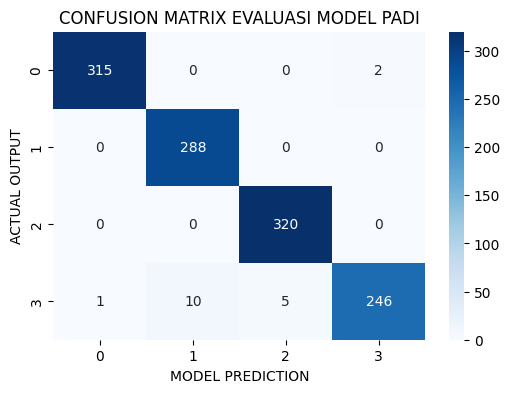

In [9]:
# TAHAP 8: EVALUASI SISTEM & ANALISIS METRIK

# MENGHITUNG METRIK EVALUASI (ACCURACY, PRECISION, RECALL, F1-SCORE)
akurasi = accuracy_score(y_test, y_pred)
# MENGGUNAKAN average='weighted' UNTUK MENDUKUNG MULTIKELAS(BANYAKNYA JENIS PENYAKIT PADI)
presisi = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("\nHASIL EVALUASI MODEL")
print(f"1. ACCURACY  : {akurasi:.4f} ({akurasi*100:.2f}%)")
print(f"2. PRECISION : {presisi:.4f}")
print(f"3. RECALL    : {recall:.4f}")
print(f"4. F1-SCORE  : {f1:.4f}")

# MENAMPILKAN CONFUSION MATRIX UNTUK MELIHAT DETAIL KESALAHAN PREDIKSI
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('CONFUSION MATRIX EVALUASI MODEL PADI')
plt.xlabel('MODEL PREDICTION')
plt.ylabel('ACTUAL OUTPUT')
plt.show()

In [16]:
# TAHAP 9: BASELINE PEMBANDING (MODEL SVM)

from sklearn.svm import SVC

# 1. INISIALISASI MODEL BASELINE PEMBANDING MENGGUNAKAN SUPPORT VECTOR MACHINE (SVM)
model_baseline = SVC(random_state=42)

# 2. TRAIN MODEL BASELINE DENGAN DATA TRAIN YANG SAMA
model_baseline.fit(X_train, y_train)

# 3. MELAKUKAN PREDICTION PADA DATA TEST
y_pred_baseline = model_baseline.predict(X_test)

# 4. EVALUASI ACCURACY BASELINE
akurasi_baseline = accuracy_score(y_test, y_pred_baseline)

print("PERBANDINGAN PERFORMA MODEL")
print(f"1. ACCURACY MAIN MODEL (RANDOM FOREST) : {akurasi*100:.2f}%")
print(f"2. ACCURACY BASELINE MODEL (SVM)       : {akurasi_baseline*100:.2f}%")

# KESIMPULAN YANG DISESUAIKAN SECARA OBJEKTIF BERDASARKAN HASIL AKTUAL EKSPERIMEN
if akurasi_baseline > akurasi:
    print("\nKESIMPULAN: MODEL BASELINE SVM MENGHASILKAN AKURASI YANG LEBIH TINGGI DIBANDINGKAN RANDOM FOREST PADA EKSPERIMEN INI")
else:
    print("\nKESIMPULAN: MODEL RANDOM FOREST TERBUKTI MEMILIKI PERFORMA LEBIH TINGGI DAN STABIL DIBANDINGKAN MODEL BASELINE SVM, SEHINGGA LAYAK DIGUNAKAN UNTUK SISTEM DIAGNOSIS PENYAKIT DAUN PADI")

PERBANDINGAN PERFORMA MODEL
1. ACCURACY MAIN MODEL (RANDOM FOREST) : 98.48%
2. ACCURACY BASELINE MODEL (SVM)       : 63.02%

KESIMPULAN: MODEL RANDOM FOREST TERBUKTI MEMILIKI PERFORMA LEBIH TINGGI DAN STABIL DIBANDINGKAN MODEL BASELINE SVM, SEHINGGA LAYAK DIGUNAKAN UNTUK SISTEM DIAGNOSIS PENYAKIT DAUN PADI


In [17]:
import joblib

# SAVE MODEL RANDOM FOREST DAN SVM KE FILE .pkl
joblib.dump(model_klasifikasi, 'model_random_forest.pkl')
joblib.dump(model_baseline, 'model_svm.pkl')

print("SAVE MODEL BERHASIL")

SAVE MODEL BERHASIL
